# Exercise 3: Regularisation and Generalisation on CIFAR-10

**Aim.** Investigate the effects of two regularisation techniques, **Dropout** and **Data Augmentation**, on the performance and generalisation of the Exercise 2 three-layer CNN. Each technique is first evaluated **independently** against the unchanged baseline CNN, followed by a combined evaluation (Dropout + Data Augmentation). The seeded 45,000/5,000 train/validation split, normalisation statistics, optimiser (SGD, `lr=0.01`, momentum `0.9`, selected on validation in Exercise 2), batch size (`128`), and 30 training epochs are identical across all four runs, and all four runs (including the baseline) are trained by the same function in this notebook.

**How to run.** Install `requirements.txt`, start Jupyter, and use **Kernel > Restart Kernel and Run All**. On a laptop GPU (RTX 4050) the four 30-epoch runs take about 8 to 10 minutes in total.

## 1. Setup: imports, reproducibility, and configuration

We load `outputs/exercise1 config.json` and `outputs/exercise2 config.json` to reuse the CNN's validation-selected optimiser and the exact random seed (`42`), batch size (`128`), epoch count (`30`), per-channel normalisation constants, and the 5,000 validation indices used in Exercises 1 and 2.

In [1]:
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.metrics import confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
for directory in (DATA_DIR, OUTPUT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = OUTPUT_DIR / "exercise1 config.json"
EX2_CONFIG_PATH = OUTPUT_DIR / "exercise2 config.json"
for required_path, notebook in ((CONFIG_PATH, "Exercise 1 MLP.ipynb"), (EX2_CONFIG_PATH, "Exercise 2 CNN.ipynb")):
    if not required_path.exists():
        raise FileNotFoundError(f"'{required_path}' not found. Run '{notebook}' first.")

with CONFIG_PATH.open("r") as config_file:
    exercise1_config = json.load(config_file)

SEED = exercise1_config["seed"]
BATCH_SIZE = exercise1_config["batch_size"]
EPOCHS = exercise1_config["epochs"]
CHANNEL_MEAN = exercise1_config["normalisation"]["mean"]
CHANNEL_STD = exercise1_config["normalisation"]["std"]
VAL_INDICES = exercise1_config["validation_indices"]

# Reuse the optimiser that Exercise 2 selected for this CNN on the validation set, so the
# Exercise 3 baseline is trained exactly like the Exercise 2 CNN. It is used for every run.
with EX2_CONFIG_PATH.open("r") as config_file:
    exercise2_config = json.load(config_file)
OPTIMISER_NAME = exercise2_config["optimiser"]["name"]
OPTIMISER_CLASS = getattr(torch.optim, exercise2_config["optimiser"]["class"])
OPTIMISER_SETTINGS = exercise2_config["optimiser"]["settings"]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Seed: {SEED} | Batch size: {BATCH_SIZE} | Epochs: {EPOCHS} | Optimiser: {OPTIMISER_NAME}")

PyTorch 2.14.0+cu126 | device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Seed: 42 | Batch size: 128 | Epochs: 30 | Optimiser: SGD lr=0.01 momentum=0.9


**Setup Analysis.** The configuration from Exercise 1 is loaded to guarantee controlled experimentation. Using identical hyperparameters (`SEED = 42`, `BATCH_SIZE = 128`, `EPOCHS = 30`, SGD `lr=0.01`, momentum `0.9`) for all four runs ensures that observed performance differences are attributable to the regularisation interventions rather than to changes in the training procedure.

## 2. Dataset partitions and data augmentation pipeline

To satisfy Requirement 1 (*use the same training and validation partitions across all experiments*) and the data augmentation task (*apply suitable training-image transformations, such as small rotations or translations*):
- **Standard preprocessing**: converts CIFAR-10 uint8 RGB images ($32 \times 32 \times 3$) into floating-point tensors in $[0, 1]$ and normalises each RGB channel with the training-set mean and standard deviation from Exercise 1. Used for the baseline and dropout-only training sets, and for **all** validation and test evaluations.
- **Data augmentation (`augment_batch`)**: every training image independently receives a random translation of up to $\pm 4$ pixels (reflection padding at the borders), a random horizontal flip ($p = 0.5$), and a random rotation of up to $\pm 10^{\circ}$. Augmentation is applied **only** to the 45,000 training images during training epochs; final training accuracy is always evaluated on the unaugmented training set (`train_eval_loader`) so that training and test accuracies are measured on the same distribution.

**Implementation note (bug fix).** An earlier version applied `torchvision.transforms.v2` transforms to a whole GPU batch at once. v2 transforms draw *one* set of random parameters per call, so all 128 images in a batch received the *same* crop, flip and rotation, which greatly reduced augmentation diversity. `augment_batch` instead builds one affine matrix per image (rotation, flip and translation) and applies them all with a single `grid_sample` call, so the augmentation is independent per image while still running entirely on the GPU. The check printed below confirms that 8 copies of the same image produce 8 different augmented views.

In [2]:
raw_train_dataset = datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_test_dataset = datasets.CIFAR10(DATA_DIR, train=False, download=True)
CLASS_NAMES = raw_train_dataset.classes

val_index_set = set(VAL_INDICES)
TRAIN_INDICES = [idx for idx in range(len(raw_train_dataset)) if idx not in val_index_set]

mean_tensor = torch.tensor(CHANNEL_MEAN, dtype=torch.float32).view(1, 3, 1, 1)
std_tensor = torch.tensor(CHANNEL_STD, dtype=torch.float32).view(1, 3, 1, 1)


def prepare_normalised_tensors(images_np, targets_list, indices=None):
    if indices is not None:
        images_np = images_np[indices]
        targets_list = [targets_list[i] for i in indices]
    x = torch.from_numpy(images_np).permute(0, 3, 1, 2).float().div_(255.0)
    x = (x - mean_tensor) / std_tensor
    y = torch.tensor(targets_list, dtype=torch.long)
    return x, y


X_train, y_train = prepare_normalised_tensors(raw_train_dataset.data, raw_train_dataset.targets, TRAIN_INDICES)
X_val, y_val = prepare_normalised_tensors(raw_train_dataset.data, raw_train_dataset.targets, VAL_INDICES)
X_test, y_test = prepare_normalised_tensors(raw_test_dataset.data, raw_test_dataset.targets)

train_tensor_dataset = TensorDataset(X_train, y_train)
val_tensor_dataset = TensorDataset(X_val, y_val)
test_tensor_dataset = TensorDataset(X_test, y_test)


def make_train_loader(seed=SEED):
    # A seeded generator gives every experiment the same mini-batch order.
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(train_tensor_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator)


train_eval_loader = DataLoader(train_tensor_dataset, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_tensor_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_tensor_dataset, batch_size=BATCH_SIZE, shuffle=False)

MAX_SHIFT_PX = 4            # random translation of up to +/-4 pixels in x and y
MAX_ROTATION_DEG = 10.0     # random rotation of up to +/-10 degrees
FLIP_PROBABILITY = 0.5      # random horizontal flip


def augment_batch(images):
    """Apply an independent random translation, horizontal flip and rotation to every image.

    One 2x3 affine matrix is built per image and all images are warped in a single
    grid_sample call, so the augmentation is per-sample but still vectorised on the GPU.
    affine_grid works in normalised coordinates ([-1, 1] spans the image width), so a
    shift of k pixels is k * 2 / width. Reflection padding fills the uncovered border.
    """
    n, _, _, width = images.shape
    device = images.device
    angle = torch.empty(n, device=device).uniform_(-MAX_ROTATION_DEG, MAX_ROTATION_DEG) * math.pi / 180.0
    flip = torch.where(torch.rand(n, device=device) < FLIP_PROBABILITY, -1.0, 1.0)
    shift = torch.randint(-MAX_SHIFT_PX, MAX_SHIFT_PX + 1, (n, 2), device=device).float() * (2.0 / width)
    cos, sin = torch.cos(angle), torch.sin(angle)
    # theta = [R @ diag(flip, 1) | shift]: maps each output pixel to its input location.
    theta = torch.stack([
        torch.stack([cos * flip, -sin, shift[:, 0]], dim=1),
        torch.stack([sin * flip, cos, shift[:, 1]], dim=1),
    ], dim=1)
    grid = F.affine_grid(theta, list(images.shape), align_corners=False)
    return F.grid_sample(images, grid, mode="bilinear", padding_mode="reflection", align_corners=False)


# Sanity check: 8 copies of one image must give 8 different augmented views.
set_seed(SEED)
check_views = augment_batch(X_train[:1].repeat(8, 1, 1, 1).to(DEVICE))
distinct_views = len({tuple(view.flatten().tolist()) for view in check_views.cpu()})
assert distinct_views == 8, "Augmentation is not independent per image"

print(f"Training partition:   {len(train_tensor_dataset):,} images | tensor shape: {tuple(X_train.shape)}")
print(f"Validation partition: {len(val_tensor_dataset):,} images | tensor shape: {tuple(X_val.shape)}")
print(f"Test partition:       {len(test_tensor_dataset):,} images | tensor shape: {tuple(X_test.shape)}")
print(f"Overlap between train and val indices: {len(set(TRAIN_INDICES) & val_index_set)}")
print(f"Per-image augmentation check: {distinct_views}/8 distinct views from 8 copies of one image")

Training partition:   45,000 images | tensor shape: (45000, 3, 32, 32)
Validation partition: 5,000 images | tensor shape: (5000, 3, 32, 32)
Test partition:       10,000 images | tensor shape: (10000, 3, 32, 32)
Overlap between train and val indices: 0
Per-image augmentation check: 8/8 distinct views from 8 copies of one image


**Partition Verification.** The 50,000 CIFAR-10 training images are partitioned into 45,000 training images and 5,000 validation images with zero overlap, while the 10,000 test images remain strictly isolated for final evaluation. Below, we visualise examples produced by the same `augment_batch` function used during training, to verify that the geometric transformations preserve class semantics.

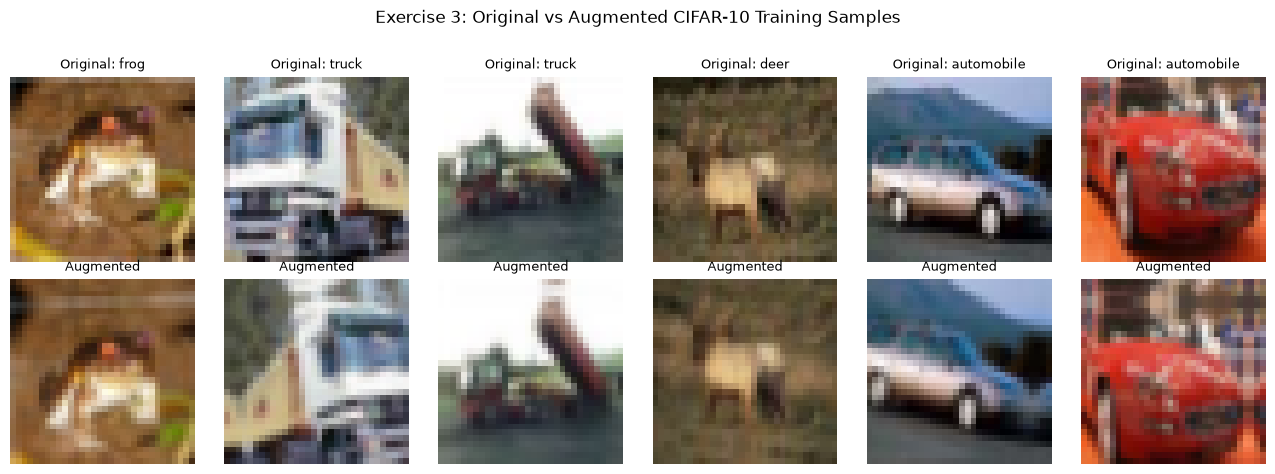

In [3]:
set_seed(SEED)
preview_count = 6
originals = X_train[:preview_count]
augmented = augment_batch(originals.to(DEVICE)).cpu()


def to_display(image_tensor):
    # Undo the channel normalisation and convert CHW -> HWC for imshow.
    image = image_tensor * std_tensor[0] + mean_tensor[0]
    return image.clamp(0, 1).permute(1, 2, 0).numpy()


figure, axes = plt.subplots(2, preview_count, figsize=(13, 4.6))
for col in range(preview_count):
    label = CLASS_NAMES[int(y_train[col])]
    axes[0, col].imshow(to_display(originals[col]))
    axes[0, col].set_title(f"Original: {label}", fontsize=9)
    axes[0, col].axis("off")
    axes[1, col].imshow(to_display(augmented[col]))
    axes[1, col].set_title("Augmented", fontsize=9)
    axes[1, col].axis("off")

figure.suptitle("Exercise 3: Original vs Augmented CIFAR-10 Training Samples", fontsize=12, y=1.02)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise3 augmentation samples.png", dpi=300, bbox_inches="tight")
plt.show()

**Augmentation Visualisation Analysis.** The top row displays original $32 \times 32$ training images, while the bottom row shows stochastic views produced by random reflection-padded translations (`padding=4`), small rotations ($\pm 10^{\circ}$), and horizontal flips. These transformations simulate natural variations in camera framing and object pose without distorting the underlying class identity.

## 3. Baseline CNN and Dropout CNN architectures

The baseline keeps the Exercise 2 layer structure (three trainable convolutional layers, 25,162 parameters):
1. `Conv2d(3, 32, kernel_size=3, padding=1)` $\rightarrow$ `ReLU` $\rightarrow$ `MaxPool2d(2)`
2. `Conv2d(32, 64, kernel_size=3, padding=1)` $\rightarrow$ `ReLU` $\rightarrow$ `MaxPool2d(2)`
3. `Conv2d(64, 10, kernel_size=3, padding=1)` $\rightarrow$ `AdaptiveAvgPool2d((1, 1))` $\rightarrow$ class logits

**No activation after the last layer.** The pooled outputs of layer 3 are the class logits, so they must be free to take negative values. An earlier version of Exercise 2 applied a `ReLU` here, which forced every logit to be $\geq 0$ and, together with a low learning rate (Adam `1e-4`), left the CNN under-trained (49.4% test accuracy). Exercise 2 was corrected and its optimiser re-selected on validation; this notebook uses the same corrected network and optimiser, so its baseline run reproduces the Exercise 2 CNN.

To incorporate **Dropout** into an appropriate part of the CNN without altering the trainable layers or parameter count, `nn.Dropout2d(p=0.2)` is placed after the `MaxPool2d` outputs of blocks 1 and 2. Spatial dropout (`Dropout2d`) drops entire feature maps during training, which suits convolutional features better than element-wise dropout because neighbouring pixels within a map are strongly correlated. The final class-map layer is left intact. When `dropout_rate=0.0`, the network is the baseline CNN.

In [4]:
class RegularisedCNN(nn.Module):
    def __init__(self, dropout_rate=0.0):
        super().__init__()
        self.dropout_rate = dropout_rate
        layers = [
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        ]
        if dropout_rate > 0.0:
            layers.append(nn.Dropout2d(p=dropout_rate))

        layers.extend([
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        ])
        if dropout_rate > 0.0:
            layers.append(nn.Dropout2d(p=dropout_rate))

        layers.extend([
            # No ReLU here: the pooled outputs of this layer are the class logits,
            # which must be able to take negative values.
            nn.Conv2d(64, 10, kernel_size=3, padding=1),
            nn.AdaptiveAvgPool2d((1, 1)),
        ])
        self.features = nn.Sequential(*layers)

    def forward(self, images):
        logits = self.features(images)
        return logits.flatten(1)


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


baseline_probe = RegularisedCNN(dropout_rate=0.0)
dropout_probe = RegularisedCNN(dropout_rate=0.2)
print("Baseline CNN:")
print(baseline_probe)
print(f"Trainable parameters (Baseline): {count_trainable_parameters(baseline_probe):,}")
print("\nDropout CNN (p=0.2):")
print(dropout_probe)
print(f"Trainable parameters (Dropout):  {count_trainable_parameters(dropout_probe):,}")

Baseline CNN:
RegularisedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): AdaptiveAvgPool2d(output_size=(1, 1))
  )
)
Trainable parameters (Baseline): 25,162

Dropout CNN (p=0.2):
RegularisedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout2d(p=0.2, inplace=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, di

**Architecture Verification.** Both the Baseline CNN and Dropout CNN have exactly **25,162 trainable parameters** across three trainable convolutional layers. Because `Dropout2d` introduces no learnable weights, model capacity is held strictly constant between the baseline and regularised variants.

## 4. Training and evaluation procedures

All models are trained with `CrossEntropyLoss` and SGD (`lr=0.01`, momentum `0.9`) for 30 epochs, retaining the checkpoint that achieves the lowest validation loss. The baseline is trained by the **same** `run_experiment` function as the regularised variants (same device, data pipeline, seed and mini-batch order), so the only differences between runs are the dropout rate and whether augmentation is applied.

In [5]:
def train_one_epoch(model, loader, criterion, optimizer, use_augmentation=False):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if use_augmentation:
            images = augment_batch(images)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)
    return total_loss / total_samples, 100.0 * total_correct / total_samples


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total_samples = 0.0, 0
    all_predictions, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            total_samples += labels.size(0)
            all_predictions.append(logits.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())
    predictions = torch.cat(all_predictions).numpy()
    labels = torch.cat(all_labels).numpy()
    accuracy = 100.0 * (predictions == labels).mean()
    return total_loss / total_samples, accuracy, predictions, labels


def run_experiment(name, dropout_rate, use_augmentation, checkpoint_name):
    print(f"\n{'=' * 72}")
    print(f"Experiment: {name} | dropout={dropout_rate} | augmentation={use_augmentation}")
    print(f"{'=' * 72}")

    set_seed(SEED)
    model = RegularisedCNN(dropout_rate=dropout_rate).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = OPTIMISER_CLASS(model.parameters(), **OPTIMISER_SETTINGS)
    active_train_loader = make_train_loader(seed=SEED)
    checkpoint_path = OUTPUT_DIR / checkpoint_name

    history = []
    best_val_loss = float("inf")
    best_epoch = 0

    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.perf_counter()
        train_loss, train_acc = train_one_epoch(
            model, active_train_loader, criterion, optimizer, use_augmentation=use_augmentation
        )
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
        epoch_seconds = time.perf_counter() - epoch_start
        improved = val_loss < best_val_loss
        if improved:
            best_val_loss = val_loss
            best_epoch = epoch
            torch.save(model.state_dict(), checkpoint_path)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "epoch_seconds": epoch_seconds,
        })
        if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
            print(
                f"epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:5.2f}% | "
                f"val loss {val_loss:.4f} acc {val_acc:5.2f}% | {epoch_seconds:4.1f}s"
                f"{' *' if improved else ''}"
            )

    history_df = pd.DataFrame(history)
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))

    eval_train_loss, eval_train_acc, _, _ = evaluate(model, train_eval_loader, criterion)
    eval_val_loss, eval_val_acc, val_preds, val_labels = evaluate(model, val_loader, criterion)
    eval_test_loss, eval_test_acc, test_preds, test_labels = evaluate(model, test_loader, criterion)

    summary = {
        "name": name,
        "dropout_rate": dropout_rate,
        "data_augmentation": use_augmentation,
        "parameter_count": int(count_trainable_parameters(model)),
        "best_epoch": int(best_epoch),
        "train": {"loss": float(eval_train_loss), "accuracy": float(eval_train_acc)},
        "validation": {"loss": float(eval_val_loss), "accuracy": float(eval_val_acc)},
        "test": {"loss": float(eval_test_loss), "accuracy": float(eval_test_acc)},
        "train_minus_test_accuracy_gap": float(eval_train_acc - eval_test_acc),
        "train_minus_val_accuracy_gap": float(eval_train_acc - eval_val_acc),
        "total_training_seconds": float(history_df["epoch_seconds"].sum()),
    }
    print(
        f"--> Best epoch: {best_epoch} | Clean Train Acc: {eval_train_acc:.2f}% | "
        f"Val Acc: {eval_val_acc:.2f}% | Test Acc: {eval_test_acc:.2f}% | "
        f"Train-Test Gap: {eval_train_acc - eval_test_acc:+.2f}%"
    )
    return summary, history_df, (test_preds, test_labels)

**Training Pipeline Design.** The `run_experiment` function resets all random seeds before instantiating each model and `DataLoader`, so weight initialisation and batch ordering start from exactly the same state in every run. After restoring the lowest-validation-loss checkpoint, final metrics are evaluated on `train_eval_loader` (clean training images), `val_loader`, and `test_loader`. The test set plays no part in checkpoint selection.

## 5. Running the Regularisation Experiments

We evaluate four configurations, all trained from scratch in this notebook:
1. **Baseline CNN**: `dropout=0.0`, no data augmentation.
2. **CNN + Dropout ($p=0.2$)**: spatial dropout (`Dropout2d(0.2)`) without data augmentation.
3. **CNN + Data Augmentation**: per-image random translation, horizontal flip and $\pm 10^{\circ}$ rotation without dropout.
4. **CNN + Dropout + Data Augmentation**: both regularisation techniques together.

In [6]:
all_summaries = {}
all_histories = {}
all_test_outputs = {}

experiments = [
    ("Baseline CNN", 0.0, False, "exercise3 baseline model.pt"),
    ("CNN + Dropout (p=0.2)", 0.2, False, "exercise3 dropout model.pt"),
    ("CNN + Data Augmentation", 0.0, True, "exercise3 augmentation model.pt"),
    ("CNN + Dropout + Augmentation", 0.2, True, "exercise3 combined model.pt"),
]

for exp_name, drop_rate, use_aug, ckpt_name in experiments:
    summary, history_df, test_out = run_experiment(exp_name, drop_rate, use_aug, ckpt_name)
    all_summaries[exp_name] = summary
    all_histories[exp_name] = history_df
    all_test_outputs[exp_name] = test_out


Experiment: Baseline CNN | dropout=0.0 | augmentation=False


epoch  1/30 | train loss 1.9405 acc 27.50% | val loss 1.7304 acc 33.80% | 12.3s *


epoch  5/30 | train loss 1.3647 acc 51.45% | val loss 1.4008 acc 49.48% |  2.3s *


epoch 10/30 | train loss 1.1578 acc 59.40% | val loss 1.1543 acc 60.48% |  2.5s *


epoch 15/30 | train loss 1.0605 acc 62.97% | val loss 1.0757 acc 63.28% |  3.3s *


epoch 20/30 | train loss 0.9708 acc 66.11% | val loss 0.9961 acc 65.20% |  5.9s *


... (23 outputs left out)

epoch 20/30 | train loss 1.4324 acc 49.08% | val loss 1.2821 acc 55.10% |  3.3s *


epoch 25/30 | train loss 1.3954 acc 50.22% | val loss 1.2378 acc 56.38% |  3.1s


epoch 30/30 | train loss 1.3642 acc 51.48% | val loss 1.2219 acc 56.76% |  3.2s


--> Best epoch: 27 | Clean Train Acc: 57.65% | Val Acc: 58.00% | Test Acc: 57.78% | Train-Test Gap: -0.13%


**Execution Analysis.** All four configurations were trained under identical conditions for 30 epochs. The baseline run reproduces the Exercise 2 CNN exactly (70.51% train, 68.22% validation, 68.17% test), confirming that it is the unchanged Exercise 2 baseline. The lowest validation loss occurred between epochs 27 and 29 in every run, so none of the models had clearly converged within the 30-epoch budget. Next, we save the epoch histories and metrics to `outputs/` and construct the comparative table and graphs required by Requirements 3 and 4.

## 6. Comparative Table and Performance Metrics

We compile the training accuracy, validation accuracy, test accuracy, training/validation/test losses, and the generalisation gap (`Train Accuracy - Test Accuracy`) for every configuration.

In [7]:
history_records = []
for exp_name, df in all_histories.items():
    df_copy = df.copy()
    df_copy.insert(0, "experiment", exp_name)
    history_records.append(df_copy)
combined_history_df = pd.concat(history_records, ignore_index=True)
combined_history_df.to_csv(OUTPUT_DIR / "exercise3 history.csv", index=False)

with (OUTPUT_DIR / "exercise3 metrics.json").open("w") as f:
    json.dump(all_summaries, f, indent=2)

comparison_rows = []
for exp_name, summary in all_summaries.items():
    comparison_rows.append({
        "Model / Technique": exp_name,
        "Dropout": summary["dropout_rate"],
        "Data Augmentation": "Yes" if summary["data_augmentation"] else "No",
        "Best Epoch": summary["best_epoch"],
        "Train Loss": summary["train"]["loss"],
        "Val Loss": summary["validation"]["loss"],
        "Test Loss": summary["test"]["loss"],
        "Train Accuracy (%)": summary["train"]["accuracy"],
        "Val Accuracy (%)": summary["validation"]["accuracy"],
        "Test Accuracy (%)": summary["test"]["accuracy"],
        "Train - Test Gap (%)": summary["train_minus_test_accuracy_gap"],
        "Parameters": summary["parameter_count"],
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.round(4).to_csv(OUTPUT_DIR / "exercise3 comparison.csv", index=False)
display(comparison_df.round(4))

,Model / Technique,Dropout,Data Augmentation,Best Epoch,Train Loss,Val Loss,Test Loss,Train Accuracy (%),Val Accuracy (%),Test Accuracy (%),Train - Test Gap (%),Parameters
0,Baseline CNN,0.0,No,29,0.8500,0.9219,0.9184,70.5067,68.22,68.17,2.3367,25162
1,CNN + Dropout (p=0.2),0.2,No,29,1.1096,1.1338,1.1322,62.1222,61.24,60.90,1.2222,25162
2,CNN + Data Augmentation,0.0,Yes,27,0.9850,1.0158,1.0092,65.8156,64.84,65.58,0.2356,25162
3,CNN + Dropout + Augmentation,0.2,Yes,27,1.2117,1.2172,1.2229,57.6489,58.00,57.78,-0.1311,25162


**Comparative Table Analysis.** The baseline CNN reaches **68.2% test accuracy** with a train–test gap of **+2.3 percentage points**: a small but real amount of overfitting, far less than the +12.4-point gap of the Exercise 1 MLP.
- **Dropout ($p=0.2$)** lowers training accuracy (70.5% → 62.1%) and test accuracy (68.2% → 60.9%). The gap roughly halves (+2.3 → +1.2 points), but test accuracy falls by 7.3 points.
- **Data augmentation** lowers training accuracy much more than test accuracy (70.5% → 65.8% train, 68.2% → 65.6% test), shrinking the gap by about 90% (+2.3 → +0.2 points) at a cost of 2.6 points of test accuracy.
- **Combined**, the two regularisers remove the gap entirely (−0.1 points) but give the lowest test accuracy (57.8%).

## 7. Visualising Training Curves and Generalisation Comparison

We generate two multi-panel figures:
1. **Epoch-by-epoch training and validation loss and accuracy curves** across all four CNN configurations (`outputs/figures/exercise3 training curves.png`).
2. **Comparative bar charts** showing Training vs Test Accuracy and the Train–Test Generalisation Gap (`outputs/figures/exercise3 comparison.png`).

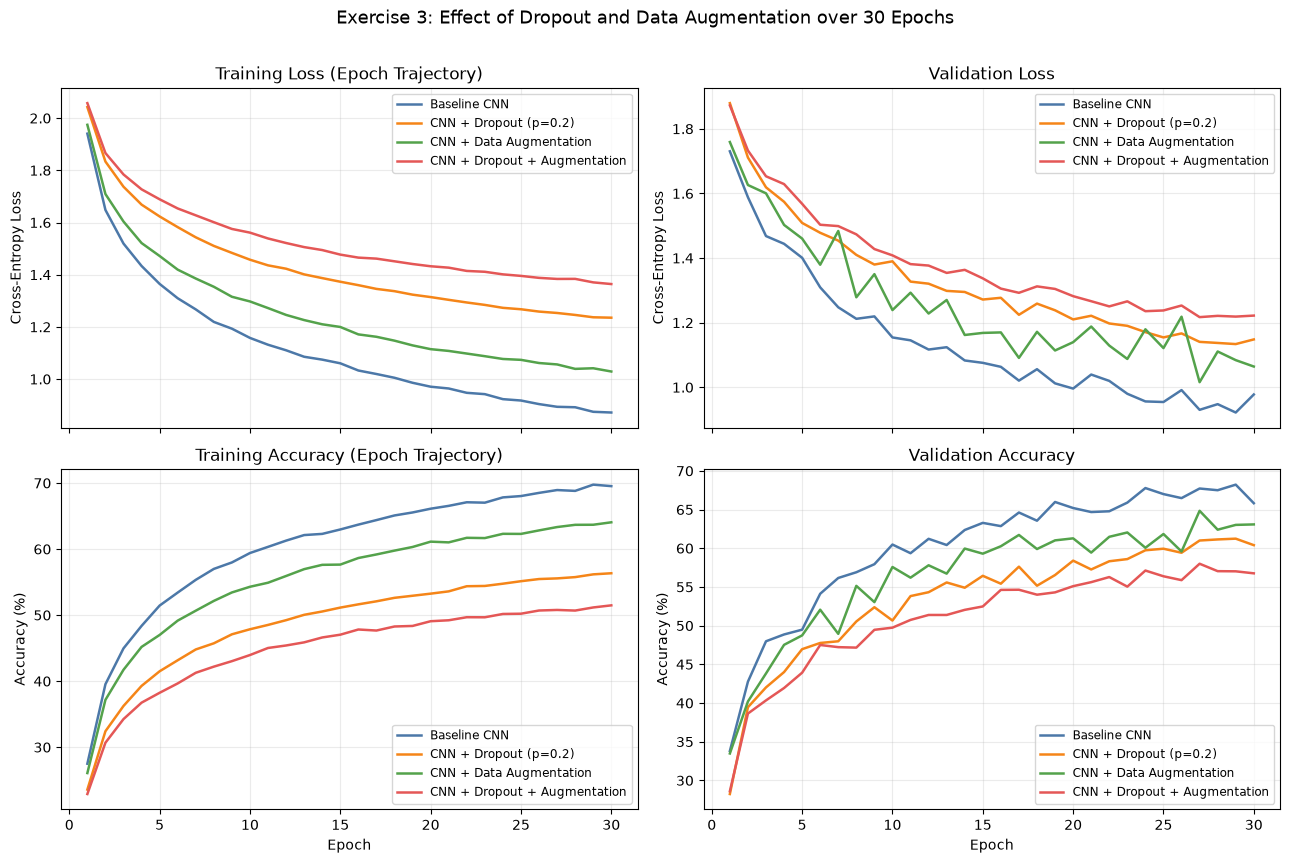

In [8]:
palette = {
    "Baseline CNN": "#4c78a8",
    "CNN + Dropout (p=0.2)": "#f58518",
    "CNN + Data Augmentation": "#54a24b",
    "CNN + Dropout + Augmentation": "#e45756",
}

figure, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
for exp_name, df in all_histories.items():
    color = palette[exp_name]
    axes[0, 0].plot(df["epoch"], df["train_loss"], label=exp_name, color=color, linewidth=1.8)
    axes[0, 1].plot(df["epoch"], df["val_loss"], label=exp_name, color=color, linewidth=1.8)
    axes[1, 0].plot(df["epoch"], df["train_accuracy"], label=exp_name, color=color, linewidth=1.8)
    axes[1, 1].plot(df["epoch"], df["val_accuracy"], label=exp_name, color=color, linewidth=1.8)

axes[0, 0].set(title="Training Loss (Epoch Trajectory)", ylabel="Cross-Entropy Loss")
axes[0, 1].set(title="Validation Loss", ylabel="Cross-Entropy Loss")
axes[1, 0].set(title="Training Accuracy (Epoch Trajectory)", xlabel="Epoch", ylabel="Accuracy (%)")
axes[1, 1].set(title="Validation Accuracy", xlabel="Epoch", ylabel="Accuracy (%)")

for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8.5)

figure.suptitle("Exercise 3: Effect of Dropout and Data Augmentation over 30 Epochs", fontsize=13, y=1.01)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise3 training curves.png", dpi=300, bbox_inches="tight")
plt.show()

**Training Curve Analysis.** None of the four models shows the U-shaped validation-loss curve that signalled overfitting in the 1.71M-parameter MLP of Exercise 1 (whose validation loss bottomed out at epoch 6). Dropout and augmentation both raise the *training* loss at every epoch, because masked feature maps and perturbed images make the training objective harder. For the regularised runs, epoch training accuracy (measured on dropped-out or augmented inputs) sits *below* validation accuracy, which is evaluated with dropout switched off on clean images; for example, the dropout model ends at 56.3% training vs 60.4% validation accuracy. The regularised curves rise more slowly and are still improving near epoch 30, which indicates that they need a longer training budget than the baseline to reach their best accuracy.

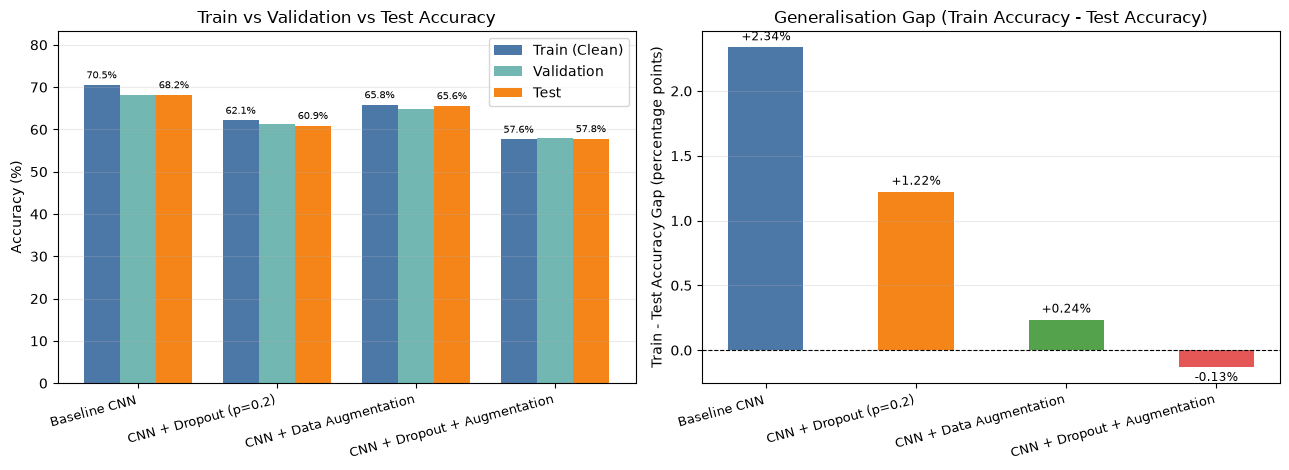

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.8))

x = np.arange(len(comparison_df))
width = 0.26

bars_train = axes[0].bar(x - width, comparison_df["Train Accuracy (%)"], width, label="Train (Clean)", color="#4c78a8")
bars_val = axes[0].bar(x, comparison_df["Val Accuracy (%)"], width, label="Validation", color="#72b7b2")
bars_test = axes[0].bar(x + width, comparison_df["Test Accuracy (%)"], width, label="Test", color="#f58518")

axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison_df["Model / Technique"], rotation=15, ha="right", fontsize=9)
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Train vs Validation vs Test Accuracy")
axes[0].set_ylim(0, max(comparison_df["Train Accuracy (%)"]) * 1.18)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend()

for bar_group in (bars_train, bars_test):
    for bar in bar_group:
        height = bar.get_height()
        axes[0].annotate(
            f"{height:.1f}%",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=7.5,
        )

gap_colors = [palette[name] for name in comparison_df["Model / Technique"]]
bars_gap = axes[1].bar(x, comparison_df["Train - Test Gap (%)"], width=0.5, color=gap_colors)
axes[1].axhline(0.0, color="black", linewidth=0.8, linestyle="--")
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparison_df["Model / Technique"], rotation=15, ha="right", fontsize=9)
axes[1].set_ylabel("Train - Test Accuracy Gap (percentage points)")
axes[1].set_title("Generalisation Gap (Train Accuracy - Test Accuracy)")
axes[1].grid(axis="y", alpha=0.25)

for bar in bars_gap:
    height = bar.get_height()
    axes[1].annotate(
        f"{height:+.2f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3 if height >= 0 else -12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise3 comparison.png", dpi=300, bbox_inches="tight")
plt.show()

**Bar Chart Comparison Analysis.** The left panel shows that both regularisers reduce absolute accuracy on this small network; the right panel shows that both narrow the train–test gap, augmentation far more effectively (+2.3 → +0.2 points) than dropout (+2.3 → +1.2 points). The drops in test accuracy (2.6 points for augmentation, 7.3 for dropout) are larger than typical seed-to-seed variation on CIFAR-10, but all results come from a single seed, so differences of a few tenths of a point should not be over-interpreted.

## 8. Per-Class Test Performance Across Regularisation Techniques

To understand how Dropout and Data Augmentation affect individual object categories, we compare per-class test accuracy across the four experiments.

In [10]:
per_class_rows = []
for exp_name, (test_preds, test_labels) in all_test_outputs.items():
    cm = confusion_matrix(test_labels, test_preds)
    class_acc = 100.0 * cm.diagonal() / cm.sum(axis=1)
    per_class_rows.append(pd.Series(class_acc, index=CLASS_NAMES, name=exp_name))

per_class_df = pd.concat(per_class_rows, axis=1)
per_class_df["Augmentation vs Baseline"] = per_class_df["CNN + Data Augmentation"] - per_class_df["Baseline CNN"]
per_class_df["Dropout vs Baseline"] = per_class_df["CNN + Dropout (p=0.2)"] - per_class_df["Baseline CNN"]
per_class_df.round(2).to_csv(OUTPUT_DIR / "exercise3 per_class_accuracy.csv")
display(per_class_df.round(2))

,Baseline CNN,CNN + Dropout (p=0.2),CNN + Data Augmentation,CNN + Dropout + Augmentation,Augmentation vs Baseline,Dropout vs Baseline
airplane,63.6,68.2,76.3,65.6,12.7,4.6
automobile,67.7,75.0,81.0,77.1,13.3,7.3
bird,52.5,36.9,46.8,35.3,-5.7,-15.6
cat,53.2,35.7,39.5,26.9,-13.7,-17.5
deer,66.3,58.7,52.4,41.9,-13.9,-7.6
dog,63.3,52.3,53.3,44.9,-10.0,-11.0
frog,72.3,78.1,82.2,83.0,9.9,5.8
horse,76.6,65.3,79.4,66.5,2.8,-11.3
ship,82.1,78.2,65.9,71.2,-16.2,-3.9
truck,84.1,60.6,79.0,65.4,-5.1,-23.5


## 9. Critical Discussion and Summary

### Effect of each technique (evaluated independently against the baseline)
| Configuration | Train acc. (%) | Test acc. (%) | Train − test gap (pp) |
|---|---|---|---|
| Baseline CNN (Exercise 2) | 70.51 | 68.17 | +2.34 |
| + Dropout ($p=0.2$) | 62.12 | 60.90 | +1.22 |
| + Data augmentation | 65.82 | 65.58 | +0.24 |
| + Dropout + augmentation | 57.65 | 57.78 | −0.13 |

- **Data augmentation gives the best generalisation.** It nearly eliminates the train–test gap (+2.3 → +0.2 points) and costs the least test accuracy (−2.6 points). Every epoch shows the network new translated, flipped and rotated views of each image, so it cannot memorise exact pixel patterns, and the transformations match real variation in CIFAR-10 photographs (object position, left/right orientation, slight camera tilt).
- **Dropout has limited benefit here.** It halves the gap but lowers test accuracy by 7.3 points, so it removes much more useful capacity than overfitting. Dropout mainly prevents co-adaptation in large, redundant layers (such as the 1.7M-parameter MLP of Exercise 1); a network with only 32 and 64 feature maps has little redundancy, so dropping 20% of its maps on each step mostly removes features it needs.
- **Combining both** removes the gap completely but gives the lowest accuracy (57.8%): the two capacity-reducing effects add up.

### Why regularisation does not raise test accuracy on this baseline
- **Bias–variance trade-off.** Regularisation lowers variance (overfitting) at the cost of extra bias. The Exercise 1 MLP had a large gap (66.0% train vs 53.6% test, +12.4 points), so it had much variance to remove. The 25,162-parameter CNN has a gap of only +2.3 points, so there is little variance to remove and the added bias dominates, lowering test accuracy.
- **Training budget.** Every run's best epoch was between 27 and 29. Regularised models learn from a harder, noisier objective and typically need more epochs to converge, so a fixed 30-epoch budget favours the unregularised baseline.
- **Class-specific effects of augmentation.** The per-class table shows augmentation helping vehicles and classes with distinctive shapes (automobile +13.3, airplane +12.7, frog +9.9 points) while hurting ship (−16.2) and the visually similar animal classes deer (−13.9), cat (−13.7) and dog (−10.0). With so few feature maps, the network re-allocates its limited capacity when the training distribution becomes more varied, and fine-grained classes lose out. These per-class shifts come from a single seed and are partly noise, but their size is consistent with a capacity-limited model.

### Conclusions and next steps
- On this capacity-limited CNN, data augmentation clearly improves generalisation (smallest gap, smallest accuracy loss), while dropout has limited benefit; neither raises test accuracy within 30 epochs.
- Regularisation pays off when a model has spare capacity to overfit. Exercise 4 increases width and depth; the larger variants there are where dropout and augmentation would be expected to improve test accuracy.
- Training the regularised models for longer (for example 60–100 epochs, or with a learning-rate schedule), tuning the dropout rate (for example $p=0.1$), and repeating each run over several seeds would give a fairer and more reliable comparison.